In [1]:
x=1

In [26]:
import scanpy as sc
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
adata = sc.read('/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/multigrate_mil/imc_grade/df81fb9f2d_adata_analysis_annotated.h5ad')
adata

AnnData object with n_obs × n_vars = 374964 × 38
    obs: 'id', 'core', 'PID', 'location', 'grade', 'tumor_type', 'tumor_size', 'gender', 'menopausal', 'PTNM_M', 'age', 'Patientstatus', 'treatment', 'PTNM_T', 'DiseaseStage', 'PTNM_N', 'AllSamplesSVSp4.Array', 'TMALocation', 'TMAxlocation', 'yLocation', 'DonorBlocklabel', 'diseasestatus', 'TMABlocklabel', 'UBTMAlocation', '%tumorcells', '%normalepithelialcells', '%stroma', '%inflammatorycells', 'SupplierPatientID', 'Yearofsamplecollection', 'PrimarySite', 'histology', 'PTNM_Radicality', 'Lymphaticinvasion', 'Venousinvasion', 'ERStatus', 'PRStatus', 'HER2Status', 'Pre-surgeryTx', 'Post-surgeryTx', 'Tag', 'Ptdiagnosis', 'DFSmonth', 'OSmonth', 'Comment', 'ER+DuctalCa', 'TripleNegDuctal', 'hormonesensitive', 'hormonerefractory', 'hormoneresistantaftersenstive', 'Fulvestran', 'microinvasion', 'I_plus_neg', 'SN', 'MIC', 'Count_Cells', 'FileName_FullStack', 'Height_FullStack', 'Width_FullStack', 'area', 'sum_area_cells', 'Subtype', 'HER2', 'ER

In [4]:
adata = adata[~adata.obs['cluster_preprocessed'].isna()].copy()
adata

AnnData object with n_obs × n_vars = 359171 × 38
    obs: 'id', 'core', 'PID', 'location', 'grade', 'tumor_type', 'tumor_size', 'gender', 'menopausal', 'PTNM_M', 'age', 'Patientstatus', 'treatment', 'PTNM_T', 'DiseaseStage', 'PTNM_N', 'AllSamplesSVSp4.Array', 'TMALocation', 'TMAxlocation', 'yLocation', 'DonorBlocklabel', 'diseasestatus', 'TMABlocklabel', 'UBTMAlocation', '%tumorcells', '%normalepithelialcells', '%stroma', '%inflammatorycells', 'SupplierPatientID', 'Yearofsamplecollection', 'PrimarySite', 'histology', 'PTNM_Radicality', 'Lymphaticinvasion', 'Venousinvasion', 'ERStatus', 'PRStatus', 'HER2Status', 'Pre-surgeryTx', 'Post-surgeryTx', 'Tag', 'Ptdiagnosis', 'DFSmonth', 'OSmonth', 'Comment', 'ER+DuctalCa', 'TripleNegDuctal', 'hormonesensitive', 'hormonerefractory', 'hormoneresistantaftersenstive', 'Fulvestran', 'microinvasion', 'I_plus_neg', 'SN', 'MIC', 'Count_Cells', 'FileName_FullStack', 'Height_FullStack', 'Width_FullStack', 'area', 'sum_area_cells', 'Subtype', 'HER2', 'ER

In [5]:
def score_top_cells(adata, sample_key, top_fraction=0.1, key_added='top_cell_attn'):
    adata.obs[key_added] = False
    for sample in np.unique(adata.obs[sample_key]):
        adata_sample = adata[adata.obs[sample_key] == sample].copy()
        threshold_idx = int(len(adata_sample) * 0.9)
        threshold_value = sorted(adata_sample.obs['cell_attn'])[threshold_idx]
        top_idx = adata_sample[adata_sample.obs['cell_attn'] >= threshold_value].obs_names
        adata.obs.loc[top_idx, 'top_cell_attn'] = True
    adata.obs[key_added] = adata.obs[key_added].astype('category')

In [6]:
score_top_cells(adata, 'core')

In [7]:
samples_to_check = []
for sample in np.unique(adata.obs['core']):
    adata_sample = adata[adata.obs['core'] == sample].copy()
    freq = adata_sample[adata_sample.obs['top_cell_attn'] == True].obs['cluster_preprocessed'].value_counts(normalize=True)
    if 'tumor cells' not in freq or freq['tumor cells'] < 0.95:
        print(sample)
        print(freq)
        samples_to_check.append(sample)

ZTMA208_slide_14_Cy3x5
cluster_preprocessed
stromal cells    0.350877
T cells          0.175439
endothelial      0.157895
tumor cells      0.157895
T and B cells    0.087719
B cells          0.070175
Name: proportion, dtype: float64
ZTMA208_slide_16_Ay16x4
cluster_preprocessed
tumor cells      0.935065
stromal cells    0.051948
T cells          0.012987
Name: proportion, dtype: float64
ZTMA208_slide_21_Cy6x1
cluster_preprocessed
stromal cells    0.488372
tumor cells      0.255814
B cells          0.116279
endothelial      0.069767
T cells          0.046512
T and B cells    0.023256
Name: proportion, dtype: float64
ZTMA208_slide_27_Cy11x2
cluster_preprocessed
tumor cells      0.272727
B cells          0.185950
macrophages      0.157025
T cells          0.152893
endothelial      0.128099
T and B cells    0.061983
stromal cells    0.041322
Name: proportion, dtype: float64
ZTMA208_slide_28_Cy14x6
cluster_preprocessed
tumor cells      0.904167
T and B cells    0.095833
Name: proportion, dty

In [8]:
len(samples_to_check)

44

In [9]:
adata[adata.obs['top_cell_attn'] == True].obs['cluster_preprocessed'].value_counts(normalize=True)

cluster_preprocessed
tumor cells      0.931633
stromal cells    0.024528
T and B cells    0.015649
T cells          0.009878
macrophages      0.008518
B cells          0.005854
endothelial      0.003940
Name: proportion, dtype: float64

In [10]:
# for sample in samples_to_check:
#     adata_img = adata[adata.obs['core']=='sample'].copy()
#     print(sample)
#     sc.pl.embedding(adata_img, 'spatial', color=['cell_attn', 'cluster_preprocessed', 'top_cell_attn'], frameon=False)

In [11]:
# so we focus on tumor cells from now on

## DE top tumor cells vs rest of tumor cells within each grade

1
AnnData object with n_obs × n_vars = 44777 × 38
    obs: 'id', 'core', 'PID', 'location', 'grade', 'tumor_type', 'tumor_size', 'gender', 'menopausal', 'PTNM_M', 'age', 'Patientstatus', 'treatment', 'PTNM_T', 'DiseaseStage', 'PTNM_N', 'AllSamplesSVSp4.Array', 'TMALocation', 'TMAxlocation', 'yLocation', 'DonorBlocklabel', 'diseasestatus', 'TMABlocklabel', 'UBTMAlocation', '%tumorcells', '%normalepithelialcells', '%stroma', '%inflammatorycells', 'SupplierPatientID', 'Yearofsamplecollection', 'PrimarySite', 'histology', 'PTNM_Radicality', 'Lymphaticinvasion', 'Venousinvasion', 'ERStatus', 'PRStatus', 'HER2Status', 'Pre-surgeryTx', 'Post-surgeryTx', 'Tag', 'Ptdiagnosis', 'DFSmonth', 'OSmonth', 'Comment', 'ER+DuctalCa', 'TripleNegDuctal', 'hormonesensitive', 'hormonerefractory', 'hormoneresistantaftersenstive', 'Fulvestran', 'microinvasion', 'I_plus_neg', 'SN', 'MIC', 'Count_Cells', 'FileName_FullStack', 'Height_FullStack', 'Width_FullStack', 'area', 'sum_area_cells', 'Subtype', 'HER2', 'E

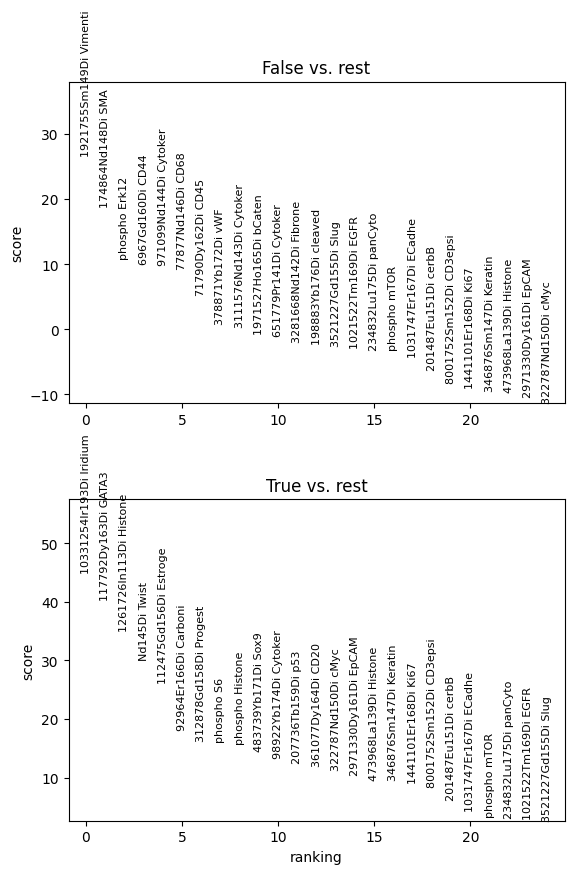

0    10331254Ir193Di Iridium
1        117792Dy163Di GATA3
2     1261726In113Di Histone
Name: names, dtype: object
0    1921755Sm149Di Vimenti
1         174864Nd148Di SMA
2             phospho Erk12
3          6967Gd160Di CD44
4     971099Nd144Di Cytoker
Name: names, dtype: object
2
AnnData object with n_obs × n_vars = 58824 × 38
    obs: 'id', 'core', 'PID', 'location', 'grade', 'tumor_type', 'tumor_size', 'gender', 'menopausal', 'PTNM_M', 'age', 'Patientstatus', 'treatment', 'PTNM_T', 'DiseaseStage', 'PTNM_N', 'AllSamplesSVSp4.Array', 'TMALocation', 'TMAxlocation', 'yLocation', 'DonorBlocklabel', 'diseasestatus', 'TMABlocklabel', 'UBTMAlocation', '%tumorcells', '%normalepithelialcells', '%stroma', '%inflammatorycells', 'SupplierPatientID', 'Yearofsamplecollection', 'PrimarySite', 'histology', 'PTNM_Radicality', 'Lymphaticinvasion', 'Venousinvasion', 'ERStatus', 'PRStatus', 'HER2Status', 'Pre-surgeryTx', 'Post-surgeryTx', 'Tag', 'Ptdiagnosis', 'DFSmonth', 'OSmonth', 'Comment', 'ER+Duct

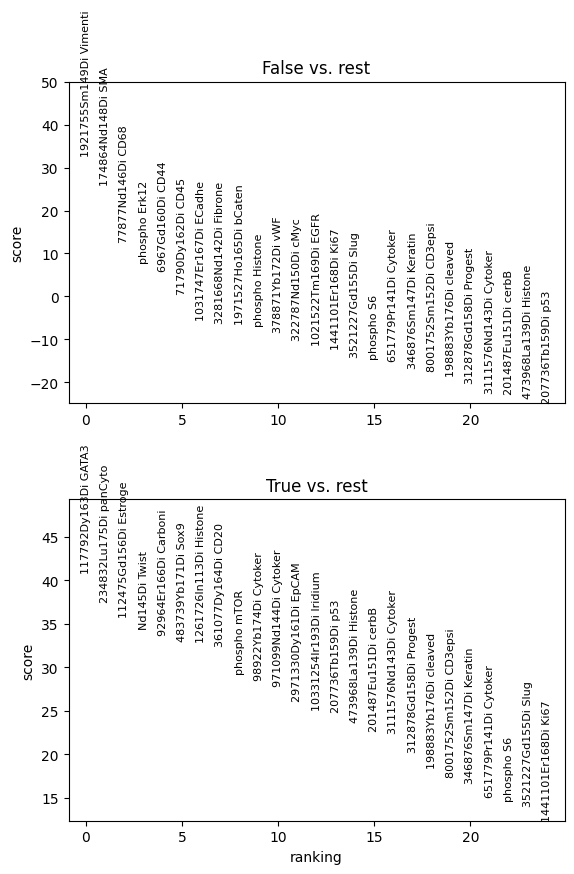

0       117792Dy163Di GATA3
1     234832Lu175Di panCyto
2    1261726In113Di Histone
3      98922Yb174Di Cytoker
4    3111576Nd143Di Cytoker
Name: names, dtype: object
0    1921755Sm149Di Vimenti
1         174864Nd148Di SMA
2             phospho Erk12
3          6967Gd160Di CD44
Name: names, dtype: object
3
AnnData object with n_obs × n_vars = 83514 × 38
    obs: 'id', 'core', 'PID', 'location', 'grade', 'tumor_type', 'tumor_size', 'gender', 'menopausal', 'PTNM_M', 'age', 'Patientstatus', 'treatment', 'PTNM_T', 'DiseaseStage', 'PTNM_N', 'AllSamplesSVSp4.Array', 'TMALocation', 'TMAxlocation', 'yLocation', 'DonorBlocklabel', 'diseasestatus', 'TMABlocklabel', 'UBTMAlocation', '%tumorcells', '%normalepithelialcells', '%stroma', '%inflammatorycells', 'SupplierPatientID', 'Yearofsamplecollection', 'PrimarySite', 'histology', 'PTNM_Radicality', 'Lymphaticinvasion', 'Venousinvasion', 'ERStatus', 'PRStatus', 'HER2Status', 'Pre-surgeryTx', 'Post-surgeryTx', 'Tag', 'Ptdiagnosis', 'DFSmonth', 'OSmo

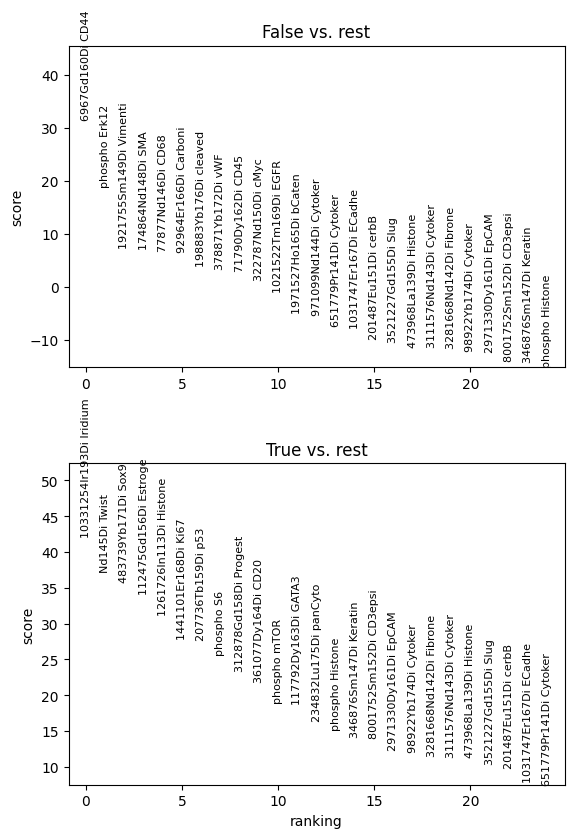

0    10331254Ir193Di Iridium
1     1261726In113Di Histone
2      234832Lu175Di panCyto
Name: names, dtype: object
0        6967Gd160Di CD44
1           phospho Erk12
2       174864Nd148Di SMA
3    92964Er166Di Carboni
Name: names, dtype: object


In [12]:
for grade in np.unique(adata.obs['grade']):
    print(grade)
    adata_grade = adata[adata.obs['grade'] == grade].copy()
    adata_grade = adata_grade[adata_grade.obs['cluster_preprocessed'] == 'tumor cells'].copy()
    print(adata_grade)
    
    sc.tl.rank_genes_groups(adata_grade, 'top_cell_attn', method='wilcoxon', key_added = "wilcoxon")

    # save results
    df = sc.get.rank_genes_groups_df(adata_grade, group='True', key='wilcoxon')
    df.to_csv(f'results/grade_{grade}_group_True.csv', index=False)
    df = sc.get.rank_genes_groups_df(adata_grade, group='False', key='wilcoxon')
    df.to_csv(f'results/grade_{grade}_group_False.csv', index=False)
    
    sc.pl.rank_genes_groups(adata_grade, n_genes=25, sharey=False, key="wilcoxon", ncols=1)

    print(sc.get.rank_genes_groups_df(adata_grade, group='True', key='wilcoxon', pval_cutoff=0.01, log2fc_min=1.5)['names'])
    print(sc.get.rank_genes_groups_df(adata_grade, group='False', key='wilcoxon', pval_cutoff=0.01, log2fc_min=1.5)['names'])

## DE between different grades within tumor cells

In [13]:
adata_tumor = adata[adata.obs['cluster_preprocessed'] == 'tumor cells'].copy()
adata_tumor

AnnData object with n_obs × n_vars = 187115 × 38
    obs: 'id', 'core', 'PID', 'location', 'grade', 'tumor_type', 'tumor_size', 'gender', 'menopausal', 'PTNM_M', 'age', 'Patientstatus', 'treatment', 'PTNM_T', 'DiseaseStage', 'PTNM_N', 'AllSamplesSVSp4.Array', 'TMALocation', 'TMAxlocation', 'yLocation', 'DonorBlocklabel', 'diseasestatus', 'TMABlocklabel', 'UBTMAlocation', '%tumorcells', '%normalepithelialcells', '%stroma', '%inflammatorycells', 'SupplierPatientID', 'Yearofsamplecollection', 'PrimarySite', 'histology', 'PTNM_Radicality', 'Lymphaticinvasion', 'Venousinvasion', 'ERStatus', 'PRStatus', 'HER2Status', 'Pre-surgeryTx', 'Post-surgeryTx', 'Tag', 'Ptdiagnosis', 'DFSmonth', 'OSmonth', 'Comment', 'ER+DuctalCa', 'TripleNegDuctal', 'hormonesensitive', 'hormonerefractory', 'hormoneresistantaftersenstive', 'Fulvestran', 'microinvasion', 'I_plus_neg', 'SN', 'MIC', 'Count_Cells', 'FileName_FullStack', 'Height_FullStack', 'Width_FullStack', 'area', 'sum_area_cells', 'Subtype', 'HER2', 'ER

In [14]:
adata_tumor.obs['grade']

id
ZTMA208_slide_51_Ay6x8_830      1
ZTMA208_slide_38_By4x7_801      2
ZTMA208_slide_16_Ay16x4_149     2
ZTMA208_slide_27_Cy11x3_1631    3
ZTMA208_slide_9_By4x2_715       2
                               ..
ZTMA208_slide_19_Cy8x7_1803     3
ZTMA208_slide_16_Ay16x7_1137    2
ZTMA208_slide_19_Cy8x4_1317     3
ZTMA208_slide_9_By4x2_934       2
ZTMA208_slide_67_Ay14x6_680     2
Name: grade, Length: 187115, dtype: category
Categories (3, object): ['1', '2', '3']

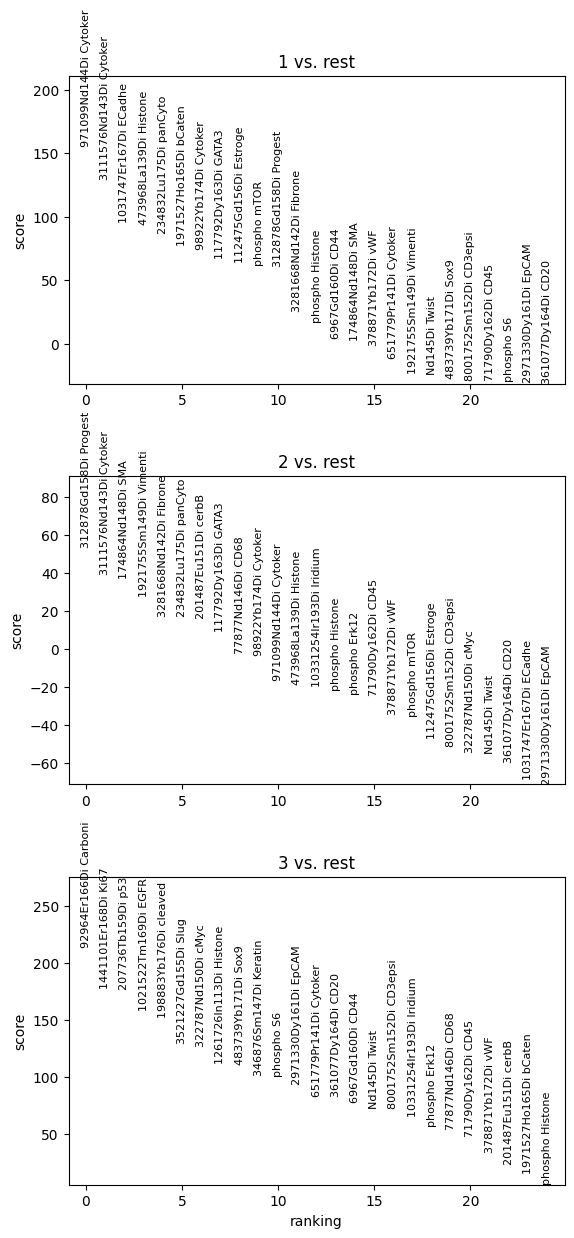

0     971099Nd144Di Cytoker
1    3111576Nd143Di Cytoker
2     1031747Er167Di ECadhe
3     234832Lu175Di panCyto
4      98922Yb174Di Cytoker
5       117792Dy163Di GATA3
6              phospho mTOR
Name: names, dtype: object
0    312878Gd158Di Progest
1        174864Nd148Di SMA
2    234832Lu175Di panCyto
Name: names, dtype: object
0       92964Er166Di Carboni
1        1441101Er168Di Ki67
2        1021522Tm169Di EGFR
3        3521227Gd155Di Slug
4     1261726In113Di Histone
5         483739Yb171Di Sox9
6           6967Gd160Di CD44
7    10331254Ir193Di Iridium
Name: names, dtype: object


In [16]:
sc.tl.rank_genes_groups(adata_tumor, 'grade', method='wilcoxon', key_added = "wilcoxon")
sc.pl.rank_genes_groups(adata_tumor, n_genes=25, sharey=False, key="wilcoxon", ncols=1)

df = sc.get.rank_genes_groups_df(adata_tumor, group='1', key='wilcoxon')
df.to_csv(f'results/grade_1_vs_rest.csv', index=False)
df = sc.get.rank_genes_groups_df(adata_tumor, group='2', key='wilcoxon')
df.to_csv(f'results/grade_2_vs_rest.csv', index=False)
df = sc.get.rank_genes_groups_df(adata_tumor, group='3', key='wilcoxon')
df.to_csv(f'results/grade_3_vs_rest.csv', index=False)

print(sc.get.rank_genes_groups_df(adata_tumor, group='1', key='wilcoxon', pval_cutoff=0.01, log2fc_min=1.5)['names'])
print(sc.get.rank_genes_groups_df(adata_tumor, group='2', key='wilcoxon', pval_cutoff=0.01, log2fc_min=1.5)['names'])
print(sc.get.rank_genes_groups_df(adata_tumor, group='3', key='wilcoxon', pval_cutoff=0.01, log2fc_min=1.5)['names'])

## DE between different grades only looking at top attn cells

In [17]:
adata_tumor_top = adata_tumor[adata_tumor.obs['top_cell_attn'] == True].copy()
adata_tumor_top

AnnData object with n_obs × n_vars = 33577 × 38
    obs: 'id', 'core', 'PID', 'location', 'grade', 'tumor_type', 'tumor_size', 'gender', 'menopausal', 'PTNM_M', 'age', 'Patientstatus', 'treatment', 'PTNM_T', 'DiseaseStage', 'PTNM_N', 'AllSamplesSVSp4.Array', 'TMALocation', 'TMAxlocation', 'yLocation', 'DonorBlocklabel', 'diseasestatus', 'TMABlocklabel', 'UBTMAlocation', '%tumorcells', '%normalepithelialcells', '%stroma', '%inflammatorycells', 'SupplierPatientID', 'Yearofsamplecollection', 'PrimarySite', 'histology', 'PTNM_Radicality', 'Lymphaticinvasion', 'Venousinvasion', 'ERStatus', 'PRStatus', 'HER2Status', 'Pre-surgeryTx', 'Post-surgeryTx', 'Tag', 'Ptdiagnosis', 'DFSmonth', 'OSmonth', 'Comment', 'ER+DuctalCa', 'TripleNegDuctal', 'hormonesensitive', 'hormonerefractory', 'hormoneresistantaftersenstive', 'Fulvestran', 'microinvasion', 'I_plus_neg', 'SN', 'MIC', 'Count_Cells', 'FileName_FullStack', 'Height_FullStack', 'Width_FullStack', 'area', 'sum_area_cells', 'Subtype', 'HER2', 'ER'

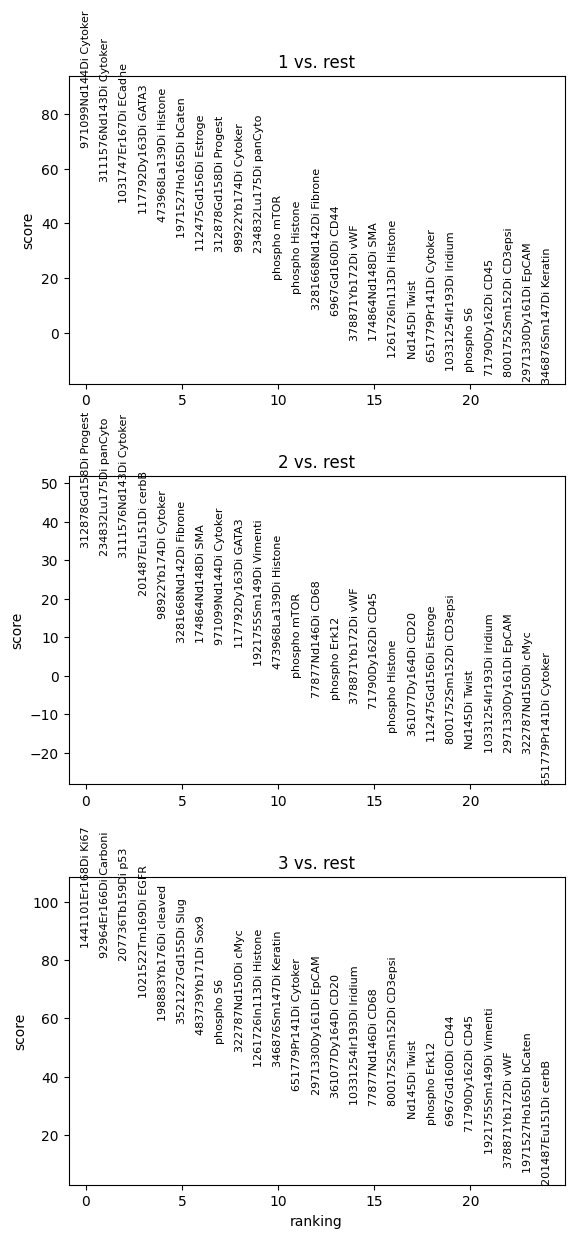

0     971099Nd144Di Cytoker
1    3111576Nd143Di Cytoker
2     1031747Er167Di ECadhe
3       117792Dy163Di GATA3
4     234832Lu175Di panCyto
5              phospho mTOR
6          6967Gd160Di CD44
Name: names, dtype: object
0     312878Gd158Di Progest
1     234832Lu175Di panCyto
2    3111576Nd143Di Cytoker
3      98922Yb174Di Cytoker
Name: names, dtype: object
0         1441101Er168Di Ki67
1        92964Er166Di Carboni
2           207736Tb159Di p53
3         1021522Tm169Di EGFR
4         3521227Gd155Di Slug
5          483739Yb171Di Sox9
6                  phospho S6
7      1261726In113Di Histone
8     10331254Ir193Di Iridium
9            6967Gd160Di CD44
10     1921755Sm149Di Vimenti
Name: names, dtype: object


In [18]:
sc.tl.rank_genes_groups(adata_tumor_top, 'grade', method='wilcoxon', key_added = "wilcoxon")
sc.pl.rank_genes_groups(adata_tumor_top, n_genes=25, sharey=False, key="wilcoxon", ncols=1)

df = sc.get.rank_genes_groups_df(adata_tumor_top, group='1', key='wilcoxon')
df.to_csv(f'results/grade_1_vs_rest_top.csv', index=False)
df = sc.get.rank_genes_groups_df(adata_tumor_top, group='2', key='wilcoxon')
df.to_csv(f'results/grade_2_vs_rest_top.csv', index=False)
df = sc.get.rank_genes_groups_df(adata_tumor_top, group='3', key='wilcoxon')
df.to_csv(f'results/grade_3_vs_rest_top.csv', index=False)

print(sc.get.rank_genes_groups_df(adata_tumor_top, group='1', key='wilcoxon', pval_cutoff=0.01, log2fc_min=1.5)['names'])
print(sc.get.rank_genes_groups_df(adata_tumor_top, group='2', key='wilcoxon', pval_cutoff=0.01, log2fc_min=1.5)['names'])
print(sc.get.rank_genes_groups_df(adata_tumor_top, group='3', key='wilcoxon', pval_cutoff=0.01, log2fc_min=1.5)['names'])

## DE between different grades only looking at top attn cells for the target grade

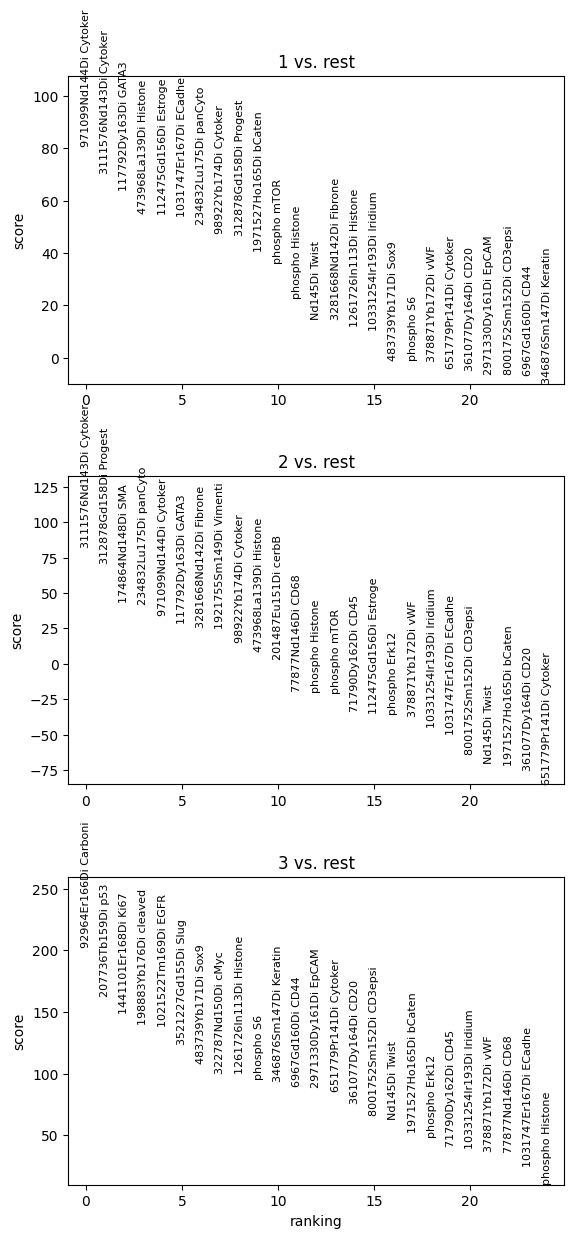

0     971099Nd144Di Cytoker
1    3111576Nd143Di Cytoker
2     1031747Er167Di ECadhe
3       117792Dy163Di GATA3
4     234832Lu175Di panCyto
5              phospho mTOR
6          6967Gd160Di CD44
Name: names, dtype: object


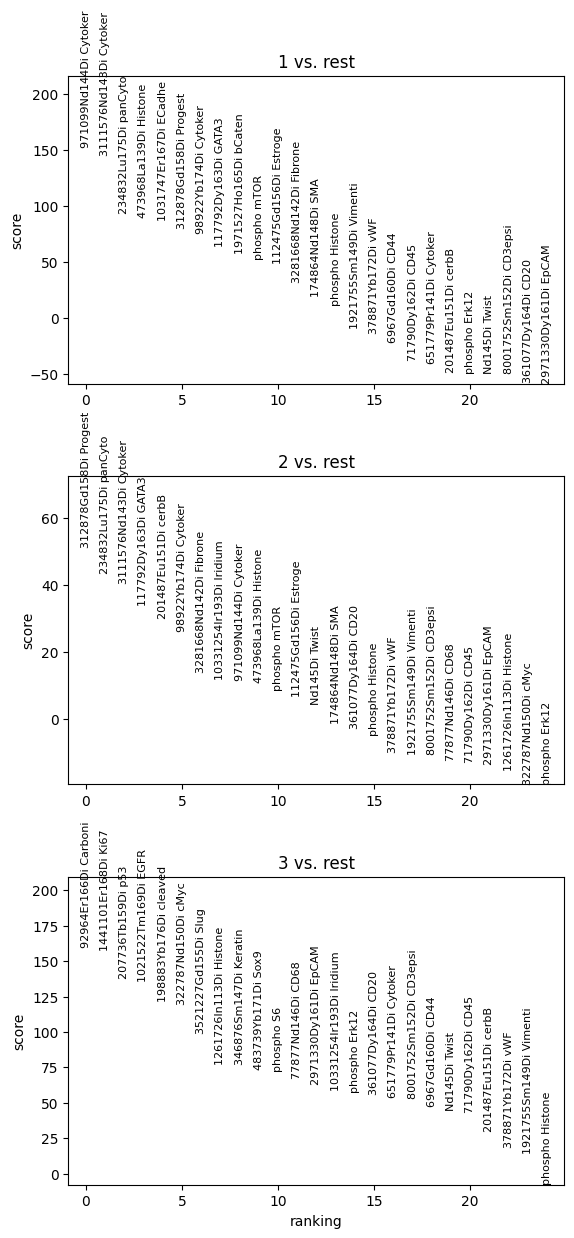

0     312878Gd158Di Progest
1     234832Lu175Di panCyto
2    3111576Nd143Di Cytoker
3      98922Yb174Di Cytoker
Name: names, dtype: object


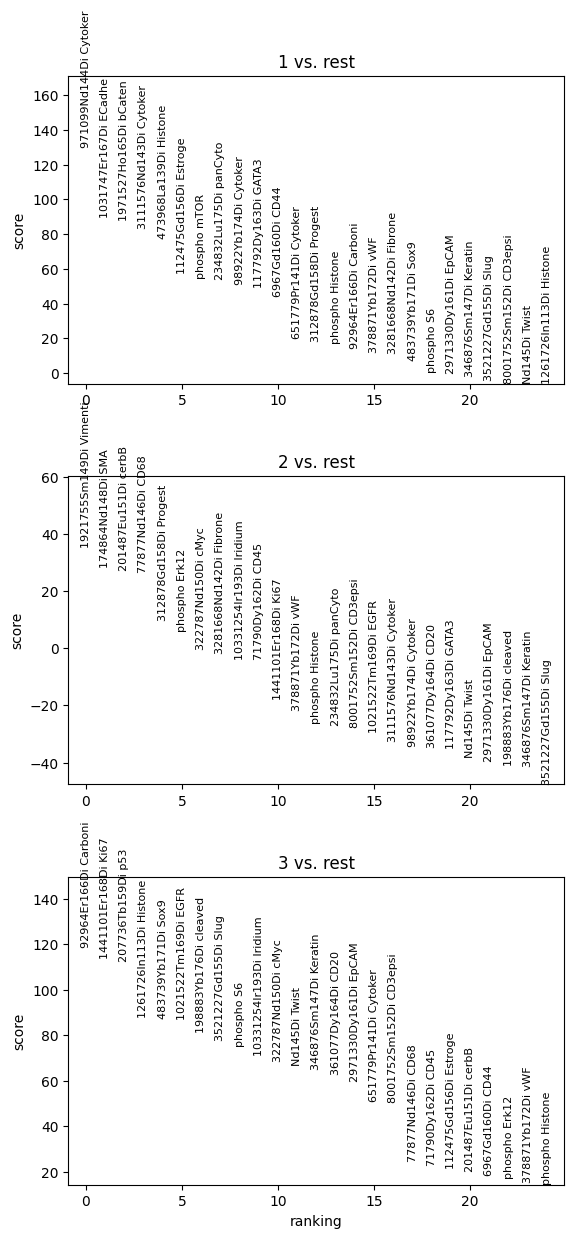

0         1441101Er168Di Ki67
1        92964Er166Di Carboni
2           207736Tb159Di p53
3         1021522Tm169Di EGFR
4         3521227Gd155Di Slug
5          483739Yb171Di Sox9
6                  phospho S6
7      1261726In113Di Histone
8     10331254Ir193Di Iridium
9            6967Gd160Di CD44
10     1921755Sm149Di Vimenti
Name: names, dtype: object


In [19]:
for grade in np.unique(adata_tumor.obs['grade']):
    adata_tmp = adata_tumor[((adata_tumor.obs['grade'] == grade) & (adata_tumor.obs['top_cell_attn'] == True)) | (adata_tumor.obs['grade'] != grade)].copy()

    sc.tl.rank_genes_groups(adata_tmp, 'grade', method='wilcoxon', key_added = "wilcoxon")

    df = sc.get.rank_genes_groups_df(adata_tmp, group=grade, key='wilcoxon')
    df.to_csv(f'results/grade_{grade}_vs_rest_top_vs_all_tumor.csv', index=False)

    sc.pl.rank_genes_groups(adata_tmp, n_genes=25, sharey=False, key="wilcoxon", ncols=1)

    print(sc.get.rank_genes_groups_df(adata_tumor_top, group=grade, key='wilcoxon', pval_cutoff=0.01, log2fc_min=1.5)['names'])

In [ ]:
# grade 1: 
# grade 2:
# grade 3: p53, Vimentin, Phospho‑S6

In [ ]:
# 0     971099Nd144Di Cytoker
# 1    3111576Nd143Di Cytoker
# 2     1031747Er167Di ECadhe
# 3     234832Lu175Di panCyto
# 4      98922Yb174Di Cytoker
# 5       117792Dy163Di GATA3
# 6              phospho mTOR
# Name: names, dtype: object
# 0    312878Gd158Di Progest
# 1        174864Nd148Di SMA
# 2    234832Lu175Di panCyto
# Name: names, dtype: object
# 0       92964Er166Di Carboni
# 1        1441101Er168Di Ki67
# 2        1021522Tm169Di EGFR
# 3        3521227Gd155Di Slug
# 4     1261726In113Di Histone
# 5         483739Yb171Di Sox9
# 6           6967Gd160Di CD44
# 7    10331254Ir193Di Iridium
# Name: names, dtype: object

In [ ]:
# 0     971099Nd144Di Cytoker
# 1    3111576Nd143Di Cytoker
# 2     1031747Er167Di ECadhe
# 3       117792Dy163Di GATA3
# 4     234832Lu175Di panCyto
# 5              phospho mTOR
# 6          6967Gd160Di CD44
# Name: names, dtype: object
# 0     312878Gd158Di Progest
# 1     234832Lu175Di panCyto
# 2    3111576Nd143Di Cytoker
# 3      98922Yb174Di Cytoker
# Name: names, dtype: object
# 0         1441101Er168Di Ki67
# 1        92964Er166Di Carboni
# 2           207736Tb159Di p53
# 3         1021522Tm169Di EGFR
# 4         3521227Gd155Di Slug
# 5          483739Yb171Di Sox9
# 6                  phospho S6
# 7      1261726In113Di Histone
# 8     10331254Ir193Di Iridium
# 9            6967Gd160Di CD44
# 10     1921755Sm149Di Vimenti
# Name: names, dtype: object